# Task 2: Trò Chơi Tank Battle — Thực Nghiệm Tìm Kiếm Đối Kháng (Adversarial Search)
Notebook này thực hiện đánh giá thực nghiệm trên cùng kịch bản và điều kiện tìm kiếm cho 4 cấu hình bắt buộc:
1. Minimax Search (Duyệt Minimax thuần túy tới trạng thái kết thúc)
2. Alpha-Beta Search (Cắt tỉa Alpha-Beta thuần túy)
3. Heuristic Minimax Search (Cắt độ sâu $d$ với hàm lượng giá chiến thuật EVAL(s))
4. Heuristic Minimax Search with Alpha-Beta Pruning (Kết hợp EVAL(s), cắt tỉa Alpha-Beta, sắp xếp nước đi Move Ordering và bảng băm Transposition Table)

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SOURCE_DIR = Path.cwd().parent
if str(SOURCE_DIR) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIR))

from task2.agents import (
    MinimaxAgent,
    AlphaBetaAgent,
    HeuristicMinimaxAgent,
    HeuristicAlphaBetaAgent,
    discover_external_agents,
)
from task2.engine import TankBattleEngine, get_all_scenarios

FIG_DIR = SOURCE_DIR.parent / 'report' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 130
print("Environment ready.")


Environment ready.


## 1. Kịch Bản Tầng 1 (Endgame Sát Nút 7x7): Đối Sánh Công Bằng Cả 4 Cấu Hình Thuật Toán

In [2]:
tier1_rows = []
for scen in get_all_scenarios(tier='tier1'):
    s0 = scen.builder()
    configs = [
        MinimaxAgent(max_ply_cap=6, name='Minimax'),
        AlphaBetaAgent(max_ply_cap=6, name='Alpha-Beta'),
        HeuristicMinimaxAgent(max_depth=4, name='Heuristic Minimax'),
        HeuristicAlphaBetaAgent(max_depth=4, name='Heuristic Alpha-Beta'),
    ]
    for agent in configs:
        act = agent.safe_choose_action(s0)
        m = agent.last_metrics
        tier1_rows.append({
            'Scenario': scen.title,
            'Configuration': agent.name,
            'Chosen Action': act,
            'Explored States': m.explored_states,
            'Search Depth': m.depth_reached,
            'Pruned Cutoffs': m.pruned_branches,
            'TT Hits': m.tt_hits,
            'Time (ms)': round(m.elapsed_ms, 2),
        })

df_tier1 = pd.DataFrame(tier1_rows)
df_tier1

,Scenario,Configuration,Chosen Action,Explored States,Search Depth,Pruned Cutoffs,TT Hits,Time (ms)
0,Endgame Center Duel (7x7),Minimax,FIRE,30278,6,0,0,974.08
1,Endgame Center Duel (7x7),Alpha-Beta,FIRE,2213,6,539,0,69.44
2,Endgame Center Duel (7x7),Heuristic Minimax,FIRE,1004,4,0,0,56.52
3,Endgame Center Duel (7x7),Heuristic Alpha-Beta,FIRE,34,4,17,2,2.16
4,Endgame Base Race (7x7),Minimax,MOVE_LEFT,35824,6,0,0,1300.61
5,Endgame Base Race (7x7),Alpha-Beta,MOVE_LEFT,975,6,395,0,39.17
6,Endgame Base Race (7x7),Heuristic Minimax,MOVE_LEFT,1369,4,0,0,60.62
7,Endgame Base Race (7x7),Heuristic Alpha-Beta,MOVE_LEFT,240,4,57,14,12.46
8,Endgame Corner Ambush (7x7),Minimax,MOVE_LEFT,39326,6,0,0,1332.85
9,Endgame Corner Ambush (7x7),Alpha-Beta,MOVE_LEFT,1418,6,402,0,56.38


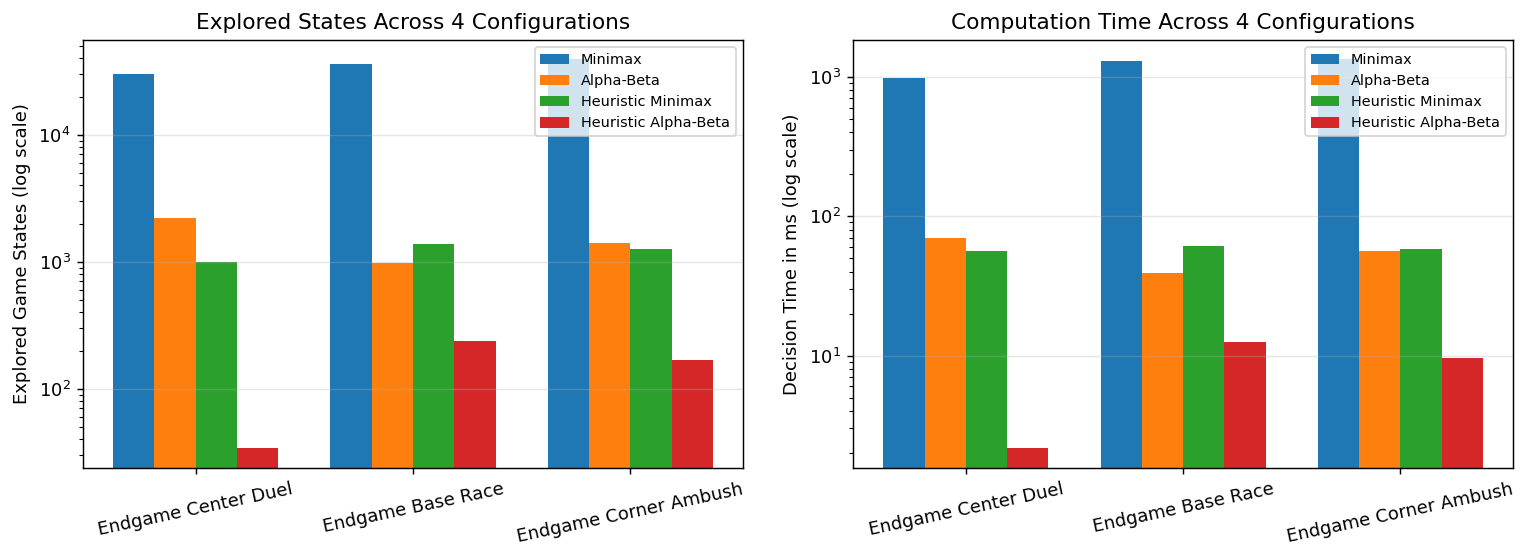

In [3]:
scenarios = df_tier1['Scenario'].unique()
configs = ['Minimax', 'Alpha-Beta', 'Heuristic Minimax', 'Heuristic Alpha-Beta']
x = np.arange(len(scenarios))
width = 0.19

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for idx, cfg in enumerate(configs):
    sub = df_tier1[df_tier1['Configuration'] == cfg]
    axes[0].bar(x + (idx - 1.5) * width, sub['Explored States'], width, label=cfg)
    axes[1].bar(x + (idx - 1.5) * width, sub['Time (ms)'], width, label=cfg)

axes[0].set_yscale('log')
axes[0].set_xticks(x)
axes[0].set_xticklabels([s.replace(' (7x7)', '') for s in scenarios], rotation=12)
axes[0].set_ylabel('Explored Game States (log scale)')
axes[0].set_title('Explored States Across 4 Configurations')
axes[0].legend(fontsize=8)
axes[0].grid(True, axis='y', alpha=0.3)

axes[1].set_yscale('log')
axes[1].set_xticks(x)
axes[1].set_xticklabels([s.replace(' (7x7)', '') for s in scenarios], rotation=12)
axes[1].set_ylabel('Decision Time in ms (log scale)')
axes[1].set_title('Computation Time Across 4 Configurations')
axes[1].legend(fontsize=8)
axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_four_algo_comparison.png', dpi=200)
plt.show()

## 2. Kịch Bản Tầng 2 (Bản Đồ Đầy Đủ 9x9 & 11x11): Khảo Sát Độ Sâu Cắt Tỉa & Đấu Đối Kháng Với Bot Nhóm Ngoài

,Map,Depth d,Algorithm,Chosen Action,Explored States,Pruned Cutoffs,TT Hits,Time (ms)
0,Classic Battle City (9x9),2,Heuristic Minimax,FIRE,31,0,0,1.84
1,Classic Battle City (9x9),2,Heuristic Alpha-Beta,FIRE,15,4,0,1.03
2,Classic Battle City (9x9),3,Heuristic Minimax,FIRE,166,0,0,7.63
3,Classic Battle City (9x9),3,Heuristic Alpha-Beta,FIRE,46,8,0,2.61
4,Classic Battle City (9x9),4,Heuristic Minimax,FIRE,895,0,0,53.24
5,Classic Battle City (9x9),4,Heuristic Alpha-Beta,FIRE,94,34,5,5.87
6,Fortress Siege (11x11),2,Heuristic Minimax,MOVE_UP,43,0,0,2.34
7,Fortress Siege (11x11),2,Heuristic Alpha-Beta,MOVE_UP,24,4,0,1.62
8,Fortress Siege (11x11),3,Heuristic Minimax,MOVE_UP,253,0,0,19.82
9,Fortress Siege (11x11),3,Heuristic Alpha-Beta,MOVE_UP,85,11,1,5.62


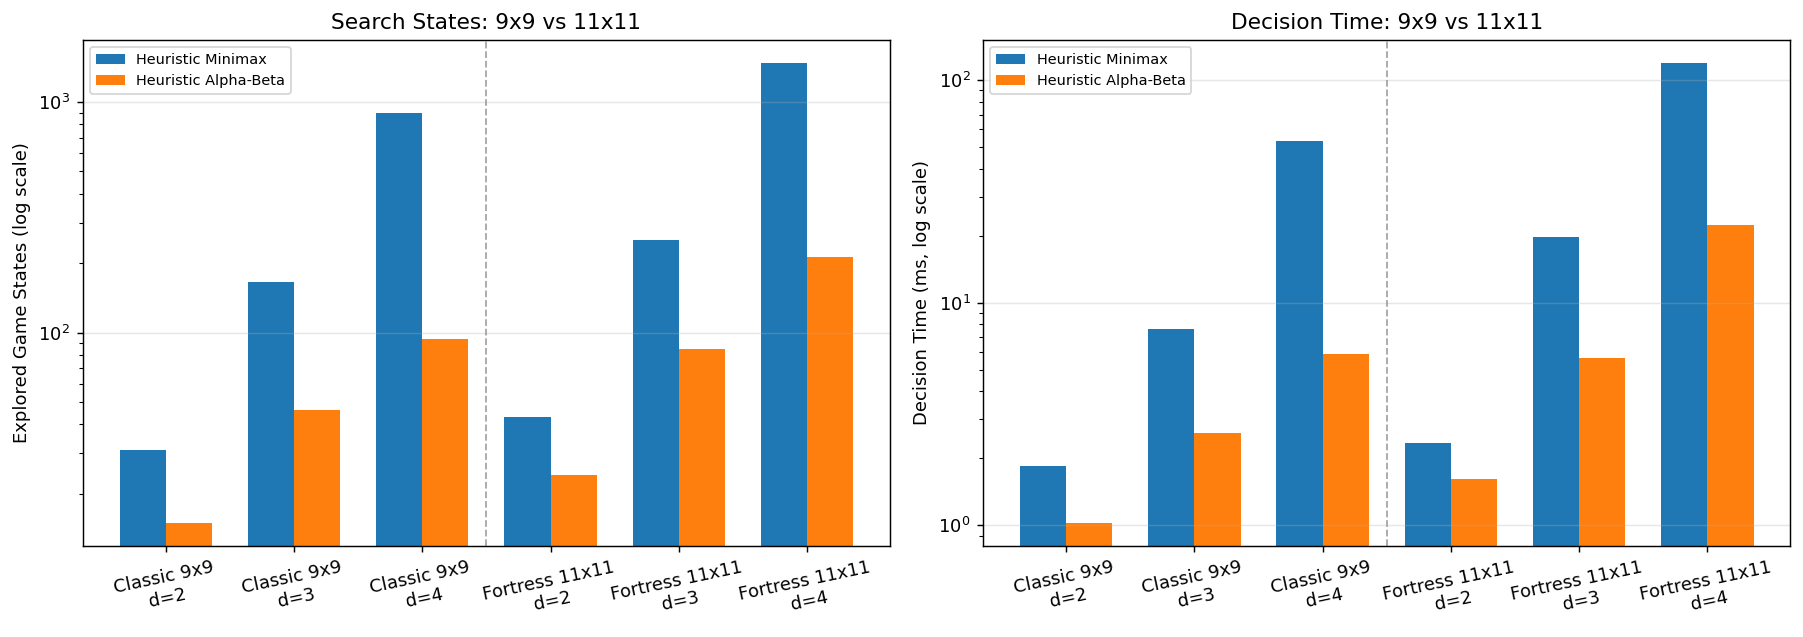

,MAX (Player 1),MIN (Player 2),Total Plies,Final HP (MAX T/B vs MIN T/B),MAX Avg ms/turn,Outcome
0,Heuristic Alpha-Beta (d=4),Heuristic Minimax (d=2),120,6/9 vs 6/9,6.34,Draw
1,Heuristic Alpha-Beta (d=4),Ext: BaseHunter (Dict API),120,6/9 vs 6/9,8.38,Draw


In [4]:
depth_rows = []
tier2_scenarios = {s.key: s for s in get_all_scenarios(tier='tier2')}
comparison_scenarios = [
    tier2_scenarios['classic_9x9'],
    tier2_scenarios['fortress_11x11'],
]
algorithm_configs = [
    (HeuristicMinimaxAgent, 'Heuristic Minimax'),
    (HeuristicAlphaBetaAgent, 'Heuristic Alpha-Beta'),
]

for scenario in comparison_scenarios:
    arena_state = scenario.builder()
    for d in [2, 3, 4]:
        for cls_ag, label in algorithm_configs:
            agent = cls_ag(max_depth=d, name=f'{label} (d={d})')
            action = agent.safe_choose_action(arena_state)
            metrics = agent.last_metrics
            depth_rows.append({
                'Map': scenario.title,
                'Depth d': d,
                'Algorithm': label,
                'Chosen Action': action,
                'Explored States': metrics.explored_states,
                    'Pruned Cutoffs': metrics.pruned_branches,
                'TT Hits': metrics.tt_hits,
                'Time (ms)': round(metrics.elapsed_ms, 2),
            })

df_depth = pd.DataFrame(depth_rows)
display(df_depth)

# Compare search cost across the 9x9 and 11x11 full-health arenas.
map_labels = {
    'Classic Battle City (9x9)': 'Classic 9x9',
    'Fortress Siege (11x11)': 'Fortress 11x11',
}
category_pairs = [
    (scenario.title, d)
    for scenario in comparison_scenarios
    for d in [2, 3, 4]
]
x = np.arange(len(category_pairs))
width = 0.36
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_metrics = [
    ('Explored States', 'Explored Game States (log scale)'),
    ('Time (ms)', 'Decision Time (ms, log scale)'),
]
for ax, (metric, ylabel) in zip(axes, plot_metrics):
    for idx, (_, algorithm) in enumerate(algorithm_configs):
        values = []
        for map_title, depth in category_pairs:
            row = df_depth[
                (df_depth['Map'] == map_title)
                & (df_depth['Depth d'] == depth)
                & (df_depth['Algorithm'] == algorithm)
            ].iloc[0]
            values.append(row[metric])
        ax.bar(
            x + (idx - 0.5) * width,
            values,
            width,
            label=algorithm,
        )
    ax.set_yscale('log')
    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{map_labels[map_title]}\nd={depth}" for map_title, depth in category_pairs],
        rotation=12,
    )
    ax.set_ylabel(ylabel)
    ax.grid(True, axis='y', alpha=0.3)
    ax.axvline(2.5, color='gray', linewidth=1, linestyle='--', alpha=0.7)
    ax.legend(fontsize=8)

axes[0].set_title('Search States: 9x9 vs 11x11')
axes[1].set_title('Decision Time: 9x9 vs 11x11')
plt.tight_layout()
plt.savefig(FIG_DIR / 'task2_tier2_9x9_vs_11x11.png', dpi=200)
plt.show()

# Head-to-head match on Open Crossfire (9x9)
ext_bots = discover_external_agents()
match_rows = []
matchups = [
    ('Heuristic Alpha-Beta (d=4)', HeuristicAlphaBetaAgent(max_depth=4), 'Heuristic Minimax (d=2)', HeuristicMinimaxAgent(max_depth=2)),
    ('Heuristic Alpha-Beta (d=4)', HeuristicAlphaBetaAgent(max_depth=4), ext_bots[0].name, ext_bots[0]),
]
for p1_name, p1, p2_name, p2 in matchups:
    st = get_all_scenarios(tier='tier2')[1].builder()
    p1_times, p2_times = [], []
    while not st.is_terminal():
        active = p1 if st.current_player == 1 else p2
        act = active.safe_choose_action(st)
        (p1_times if st.current_player == 1 else p2_times).append(active.last_metrics.elapsed_ms)
        st = TankBattleEngine.apply_action(st, act)
    w = st.winner()
    winner_str = p1_name if w == 1 else (p2_name if w == 2 else 'Draw (HP Advantage MAX)' if st.tanks[1].hp + st.bases[1].hp > st.tanks[2].hp + st.bases[2].hp else 'Draw')
    match_rows.append({
        'MAX (Player 1)': p1_name,
        'MIN (Player 2)': p2_name,
        'Total Plies': st.ply,
        'Final HP (MAX T/B vs MIN T/B)': f"{st.tanks[1].hp}/{st.bases[1].hp} vs {st.tanks[2].hp}/{st.bases[2].hp}",
        'MAX Avg ms/turn': round(sum(p1_times) / max(1, len(p1_times)), 2),
        'Outcome': winner_str,
    })
pd.DataFrame(match_rows)